### Figure
#### Examples from each dimension

In [1]:
cd /Users/cl1704/PycharmProjects/embedding_dimension/BWM

/Users/cl1704/PycharmProjects/embedding_dimension/BWM


In [2]:
import numpy as np
import pandas as pd
from Notebooks.preprocessing import *
#from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA
#from kneed import KneeLocator
from sklearn.manifold import Isomap
from matplotlib import gridspec
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from scipy.stats import special_ortho_group
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt
from datajoint_tables import *
import datajoint as dj_langdon
dj_langdon.config['database.host'] = 'datajoint-tengel.pni.princeton.edu'
dj_langdon.config['database.user'] = 'cl1704'
dj_langdon.config['database.password'] = 'wuxty2-mYdxej-kerxaq'
schema = dj_langdon.schema('langdon_ibl_manifold')
schema.spawn_missing_classes()

from sklearn.metrics import silhouette_score
import os
import scipy.optimize as opt
plt.rcParams["axes.grid"] = False
import matplotlib
matplotlib.rcParams['axes.linewidth'] = .75

[2025-05-12 11:46:42,322][INFO]: Connecting cl1704@datajoint-tengel.pni.princeton.edu:3306
[2025-05-12 11:46:42,867][INFO]: Connected cl1704@datajoint-tengel.pni.princeton.edu:3306


In [72]:
def plot_response_matrix(beryl,eid,k):
    n_time = 10
    n_splits = 10
    trial_length = .5
    n_active = 100
    sigma = 2
    # Fetch data
    spike_times = (Cluster() & {'beryl': beryl} & {'eid': eid}).fetch('spike_times')
    stimon_times, choices, sides = session_data(eid)
    n_trials = len(choices)
    print(n_trials)
    # Build response matrix. 
    response_df = binned_trials(spike_times, stimon_times, choices,
                                sides, n_time, trial_length)
    response_df["condition"] = response_df.groupby(['side', 'choice', 'neuron']).grouper.group_info[0]

    # Mean responses
    responses = df2responsematrix(response_df, sigma)
    active_neurons = np.argsort(np.mean(responses, axis=1))[-n_active:]
    responses = responses[active_neurons, :]
    
    #responses = responses[np.mean(responses, axis=1) > 1, :]
    
    # z-score
    responses = (responses - np.mean(responses, axis=1, keepdims=True)) / np.std(responses, axis=1,
                                                                                         keepdims=True)
    responses = responses[~np.isnan(responses).any(axis=1)]
    
    
    clustering = KMeans(n_clusters=k,n_init=20).fit(responses)
    
    labels  = clustering.labels_
    sort = np.argsort(labels)
    sorted_responses = responses[sort,:]
    sns.husl_palette(s=.4)
    network_pal = sns.husl_palette(pd.Series(np.sort(labels)).unique().size,s=1)
    lut = dict(zip(pd.Series(np.sort(labels)).unique(),network_pal))
    row_colors = pd.Series(np.sort(labels)).map(lut)
    g = sns.clustermap(pd.DataFrame((sorted_responses)),row_cluster=False, col_cluster=False, row_colors=row_colors,figsize=(.9,1.5), xticklabels=False, yticklabels=False,center=0)
    g.savefig('/Users/cl1704/PycharmProjects/Clustering/Figures/MainFig_2_c.jpg',
        format='jpeg',
        dpi=450,
                bbox_inches='tight'
    )

In [25]:

def plot_selectivity_space(beryl,eid,k):
    n_time = 10
    n_splits = 10
    trial_length = .5
    n_active = 100
    sigma = 2
    # Fetch data
    spike_times = (Cluster() & {'beryl': beryl} & {'eid': eid}).fetch('spike_times')
    stimon_times, choices, sides = session_data(eid)
    n_trials = len(choices)
    print(n_trials)
    # Build response matrix. 
    response_df = binned_trials(spike_times, stimon_times, choices,
                                sides, n_time, trial_length)
    response_df["condition"] = response_df.groupby(['side', 'choice', 'neuron']).grouper.group_info[0]

    # Mean responses
    responses = df2responsematrix(response_df, sigma)
    active_neurons = np.argsort(np.mean(responses, axis=1))[-n_active:]
    responses = responses[active_neurons, :]
    
    #responses = responses[np.mean(responses, axis=1) > 1, :]
    
    # z-score
    responses = (responses - np.mean(responses, axis=1, keepdims=True)) / np.std(responses, axis=1,
                                                                                         keepdims=True)
    responses = responses[~np.isnan(responses).any(axis=1)]
    n_neurons = responses.shape[0]
    
    all_responses = []
    #for fold, (train_index, test_index) in enumerate(skf.split(trials, conditions)):
    for split in range(n_splits):
        # Training responses

        sampled_df = response_df.groupby('condition').sample(frac=1.0, replace=True)

        sampled_responses = df2responsematrix(sampled_df, sigma)
        sampled_responses = sampled_responses[active_neurons, :]
        # Restrict to neurons with mean firing rate greater than 1.
        #sampled_responses = sampled_responses[np.mean(sampled_responses, axis=1) > 1, :]

        # Restrict to neurons with the highest signal-to-noise ratio.
        #neurons = np.argsort(np.mean(sampled_responses, axis=1))[-n_active:]
        #sampled_responses = sampled_responses[neurons, :]
        # standard deviation of standard deviation across neuron

        # Z-score
        sampled_responses = (sampled_responses - np.mean(sampled_responses, axis=1, keepdims=True)) / np.std(sampled_responses, axis=1,
                                                                                     keepdims=True)
        sampled_responses = sampled_responses[~np.isnan(sampled_responses).any(axis=1)]


        if sampled_responses.shape[0] == n_neurons:
            all_responses.append(sampled_responses)

    boot_responses = np.concatenate(all_responses, axis=0)
    
    # Fit K-Means
    kmeans = KMeans(n_clusters=k,n_init=20).fit(responses)
    
    # Fit LDA

    lda = LinearDiscriminantAnalysis()
    parameters = {'tol':10**np.linspace(-5,0,50)}
    from sklearn.model_selection import GridSearchCV
    clf = GridSearchCV(lda, parameters,refit=True,error_score = np.nan,cv=5)
    clf.fit(responses, kmeans.labels_)
    lda = clf.best_estimator_
    lda = PCA().fit(responses)
    # Project data
    #x_proj = lda.fit_transform(boot_responses)
    x_proj = lda.transform(boot_responses)
    
    fig = plt.figure(figsize=(1,1))
    gs = gridspec.GridSpec(1,1)
    ax=fig.add_subplot(gs[0,0])
    
    sns.scatterplot(x=x_proj[:, 0], y=x_proj[:, 1],color='lightgray',s=3,alpha=1,ax=ax)
    #sns.kdeplot(x=x_proj[:, 0], y=x_proj[:, 1],color='lightgray',levels = 100, fill = True)
    
    labels= kmeans.labels_
    network_pal = sns.husl_palette(pd.Series(np.sort(labels)).unique().size,s=1)
    lut = dict(zip(pd.Series(np.sort(labels)).unique(),network_pal))
    row_colors = pd.Series(np.sort(labels)).map(lut)

    x_proj = lda.fit_transform(responses, kmeans.labels_)
    sns.scatterplot(x=x_proj[np.argsort(kmeans.labels_), 0], y=x_proj[np.argsort(kmeans.labels_), 1],c=row_colors,s=3,alpha=1,ax=ax)
    
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.axes.get_xaxis().set_visible(False)
    ax.axes.get_yaxis().set_visible(False)
    
    

In [36]:
def plot_state_space(beryl,eid):
    n_time = 20
    n_active = 100
    palette = sns.color_palette("husl", n_colors=n_time,as_cmap=False)
    conditions = np.array([[-1,-1],
                           [-1,0],
                           [-1,1],
                           [1,-1],
                           [1,0],
                           [1,1],
               
                        ])
    n_splits = 25
    trial_length = .5
    sigma = 2
    # Fetch data
    spike_times = (Cluster() & {'beryl': beryl} & {'eid': eid}).fetch('spike_times')
    stimon_times, choices, sides = session_data(eid)
    n_trials = len(choices)
    print(n_trials)
    # Build response matrix. 
    response_df = binned_trials(spike_times, stimon_times, choices,
                                sides, n_time, trial_length)
    response_df["condition"] = response_df.groupby(['side', 'choice', 'neuron']).grouper.group_info[0]


   # response_df = response_df[response_df.choice != 0]
   # df = response_df.groupby(['trial','choice','side'])['response'].apply(lambda x: np.vstack(x)).reset_index()

   #  # Per condition means
   #  #df = df.groupby(['choice', 'side','neuron'])['response'].mean().reset_index()
   #  df['response'] = df['response'].apply(lambda x: gaussian_filter1d(x, sigma))
   # # df = df.groupby(['neuron'])['response'].apply(lambda x: np.vstack(x)).reset_index()
   # 
   #  responses = np.stack(df.response.values,axis=0)
   #  responses  = (responses - np.mean(responses, axis = (0,2),keepdims=True)) / np.std(responses, axis = (0,2),keepdims=True)
   #  
   # responses = responses[~np.isnan(responses).any(axis=1)]
    
    # Mean responses
    responses = df2responsematrix(response_df, sigma)
    #responses = responses[np.mean(responses, axis=1) > 1, :]
    active_neurons = np.argsort(np.mean(responses, axis=1))[-n_active:]
    responses = responses[active_neurons, :]
    
    # z-score
    responses = (responses - np.mean(responses, axis=1, keepdims=True)) / np.std(responses, axis=1,
                                                                                         keepdims=True)
    responses = responses[~np.isnan(responses).any(axis=1)]
    n_neurons = responses.shape[0]
    
    all_responses = []
    #for fold, (train_index, test_index) in enumerate(skf.split(trials, conditions)):
    for split in range(n_splits):
        # Training responses

        sampled_df = response_df.groupby('condition').sample(frac=0.25, replace=False)

        sampled_responses = df2responsematrix(sampled_df, sigma)
        sampled_responses = sampled_responses[active_neurons, :]
        # Restrict to neurons with mean firing rate greater than 1.
        #sampled_responses = sampled_responses[np.mean(sampled_responses, axis=1) > 1, :]

        # Restrict to neurons with the highest signal-to-noise ratio.
        #neurons = np.argsort(np.mean(sampled_responses, axis=1))[-n_active:]
        #sampled_responses = sampled_responses[neurons, :]
        # standard deviation of standard deviation across neuron

        # Z-score
        sampled_responses = (sampled_responses - np.mean(sampled_responses, axis=1, keepdims=True)) / np.std(sampled_responses, axis=1,
                                                                                     keepdims=True)
        sampled_responses = sampled_responses[~np.isnan(sampled_responses).any(axis=1)]


        if sampled_responses.shape[0] == n_neurons:
            all_responses.append(sampled_responses)

    boot_responses = np.concatenate(all_responses, axis=1)
    
    # responses = np.transpose(responses, (0,2,1))
    # responses = responses.reshape(-1,responses.shape[2])
    pca = PCA(n_components=2).fit(responses.T)
    # df.response = df.response.apply(lambda x: x.T)
    # df.response = df.response.apply(lambda x: pca.transform(x))
    proj_responses = pca.transform(responses.T).T
    # 
    # rows = []
    # for index, row in df.iterrows():
    #     for t in range(n_time):
    #         rows.append({'trial':row['trial'],
    #                      'choice':row['choice'],
    #                      'side':row['side'],
    #                      't':t * (500 / n_time),
    #                      'x': row['response'][t,0],
    #                      'y': row['response'][t,1]})
    rows = []
    for condition in range(6):
        for t in range(n_time):
            rows.append({
                         'choice':conditions[condition,0],
                         'side':conditions[condition,1],
                         't':t * (500 / n_time),
                         'x': proj_responses[0,condition*n_time+t],
                         'y': proj_responses[1,condition*n_time+t]}
                        )
    trajectory_df = pd.DataFrame(rows)
    trajectory_df = trajectory_df.groupby(['choice','side','t']).mean().reset_index()
    #palette = sns.diverging_palette(145, 300, s=60, as_cmap=True)
   # palette = sns.husl_palette(n_colors = n_time, s = 1)
    
    fig = plt.figure(figsize=(1,1))
    gs = gridspec.GridSpec(1,1)
    ax=fig.add_subplot(gs[0,0])


    palette = sns.husl_palette(n_colors = 2,s=1)
    sns.scatterplot(data = trajectory_df,x = 'x',y='y',hue='t',legend=False,ax=ax,s=4,alpha=1)
    # sns.scatterplot(data = trajectory_df,x = 'x',y='y',hue='choice',legend=False,ax=ax,s=4,alpha=1,palette =  sns.light_palette("gray",as_cmap=True))
   
    # sns.scatterplot(data = trajectory_df[trajectory_df.t>450],x = 'x',y='y',hue='choice',legend=False,ax=ax,s=3,alpha=.5,palette=palette)
    
    # Bootstrapt
    # proj_responses =pca.transform(boot_responses.T).T
    # print(proj_responses.shape)
    # rows = []
    # for split in range(len(all_responses)):
    #     for condition in range(6):
    #         for t in range(n_time):
    #             rows.append({'split':split,
    #                          'choice':conditions[condition,0],
    #                          'side':conditions[condition,1],
    #                          't':t * (500 / n_time),
    #                          'x': proj_responses[0,split*6*n_time +condition*n_time+t],
    #                          'y': proj_responses[1,split*6*n_time +condition*n_time+t]}
    #                         )
    # trajectory_df = pd.DataFrame(rows)
    # palette = sns.husl_palette(n_colors =2,s=1)
    # sns.scatterplot(data = trajectory_df,x = 'x',y='y',hue='t',legend=False,ax=ax,s=1,alpha=1,palette = sns.light_palette("gray",as_cmap=True))
    # sns.scatterplot(data = trajectory_df[trajectory_df.t>450],x = 'x',y='y',hue='choice',legend=False,ax=ax,s=1,alpha=.5,palette=palette)
    ax.axis('equal')
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.axes.get_xaxis().set_visible(False)
    ax.axes.get_yaxis().set_visible(False)
        

In [27]:
df = pd.DataFrame((Experiment_1() ).proj('eid','beryl','cosmos','n_neurons','variance','inertia','n_trials','null_param','activity_std','k','responses','p','null_inertia').fetch())
df = df[df.n_neurons>=50]

In [69]:
df[df.beryl=='ORBvl'].sort_values('k')

,beryl,cosmos,eid,n_time,n_active,sigma,trial_length,n_splits,null_param,variance,p,inertia,null_inertia,k,activity_std,n_neurons,responses,n_trials
420,ORBvl,Isocortex,8207abc6-6b23-4762-92b4-82e05bed5143,10,50,2.0,0.50,25,1.0,"[0.5009095239287881, 0.3381224608935004, 0.210...",0.000,"[0.7728264713819253, 0.5262674474910456, 0.422...","[[0.9890064495357498, 0.9908778589242787, 0.98...",5,3.99137,235,"[[0.8868694149569468, 1.0210121145809365, 1.05...",751
418,ORBvl,Isocortex,08102cfc-a040-4bcf-b63c-faa0f4914a6f,10,50,2.0,0.50,25,1.0,"[0.6683215103499819, 0.47681798244425555, 0.30...",0.000,"[0.8167165096950075, 0.6591606930289436, 0.538...","[[0.9742896518230606, 0.9564486038911153, 0.98...",6,2.31922,67,"[[-0.9197171182715779, -0.9197171182715779, -0...",406
419,ORBvl,Isocortex,1191f865-b10a-45c8-9c48-24a980fd9402,10,50,2.0,0.50,25,1.0,"[0.6955256790937541, 0.4334499361663047, 0.273...",0.000,"[0.9187008043200937, 0.6754388284847426, 0.568...","[[0.9893985919317094, 0.9678650238011752, 0.98...",6,3.90101,198,"[[0.7822522399008068, 0.5457723476935272, 0.15...",966
422,ORBvl,Isocortex,dfbe628d-365b-461c-a07f-8b9911ba83aa,10,50,2.0,0.50,25,1.0,"[0.5992776913623186, 0.44548430521599813, 0.34...",0.000,"[0.8553947789265842, 0.6069251009973615, 0.538...","[[0.948958153976842, 0.9873558799981541, 0.990...",8,1.69105,220,"[[-0.06304054312911143, 0.04321707048312564, 0...",753
421,ORBvl,Isocortex,d33baf74-263c-4b37-a0d0-b79dcb80a764,10,50,2.0,0.50,25,1.0,"[0.6677913677791849, 0.4938952822571896, 0.364...",0.003,"[0.955023522462944, 0.7027311196594441, 0.6177...","[[0.9891525492665322, 0.9903350245597312, 0.97...",9,1.70927,72,"[[-1.1939364827358392, -0.8210880255193198, -0...",427


751


/Users/cl1704/PycharmProjects/embedding_dimension/BWM/Notebooks/preprocessing.py:52: RuntimeWarning: ks_2samp: Exact calculation unsuccessful. Switching to method=asymp.
  statistic, p = ks_2samp(pre_spikes, post_spikes)


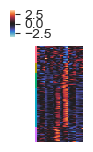

In [73]:
plot_response_matrix(beryl='ORBvl',eid='8207abc6-6b23-4762-92b4-82e05bed5143',k=5)

583


/Users/cl1704/PycharmProjects/embedding_dimension/BWM/Notebooks/preprocessing.py:52: RuntimeWarning: ks_2samp: Exact calculation unsuccessful. Switching to method=asymp.
  statistic, p = ks_2samp(pre_spikes, post_spikes)


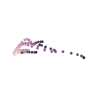

In [55]:
plot_state_space(beryl='SSp-ul',eid='e56541a5-a6d5-4750-b1fe-f6b5257bfe7c')

516


/Users/cl1704/PycharmProjects/embedding_dimension/BWM/Notebooks/preprocessing.py:52: RuntimeWarning: ks_2samp: Exact calculation unsuccessful. Switching to method=asymp.
  statistic, p = ks_2samp(pre_spikes, post_spikes)


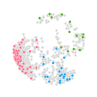

In [57]:
plot_selectivity_space(beryl='VCO',eid='71855308-7e54-41d7-a7a4-b042e78e3b4f',k=3)